In [1]:
# Import the libraries needed for stock market analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load the stock market dataset

df = pd.read_csv("stock_prices.csv")

# Display the first five rows
df.head()

,Date,Open,High,Low,Close,Volume
0,2025-01-01,145.68,149.76,144.84,148.63,376507
1,2025-01-02,149.64,151.37,149.22,149.55,703174
2,2025-01-03,149.55,150.47,148.50,149.81,222629
3,2025-01-06,150.73,155.48,149.47,153.78,608076
4,2025-01-07,155.29,156.94,154.15,155.31,185725


In [3]:
# Let's understand our dataset a little better

print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

Rows and columns: (180, 6)

Column names:
Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='str')

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    180 non-null    str    
 1   Open    180 non-null    float64
 2   High    180 non-null    float64
 3   Low     180 non-null    float64
 4   Close   180 non-null    float64
 5   Volume  180 non-null    int64  
dtypes: float64(4), int64(1), str(1)
memory usage: 10.3 KB


In [4]:
# Let's check if our data has any problems

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate rows:
0


In [5]:
# Let's clean our data before analysis

df["Date"] = pd.to_datetime(df["Date"])

# Remove repeated rows
df = df.drop_duplicates()

# Remove rows with missing important information
df = df.dropna(subset=["Date", "Close", "Volume"])

# Arrange the data from oldest to newest
df = df.sort_values("Date").reset_index(drop=True)

print("Our dataset is clean and ready!")
df.head()

Our dataset is clean and ready!


,Date,Open,High,Low,Close,Volume
0,2025-01-01,145.68,149.76,144.84,148.63,376507
1,2025-01-02,149.64,151.37,149.22,149.55,703174
2,2025-01-03,149.55,150.47,148.50,149.81,222629
3,2025-01-06,150.73,155.48,149.47,153.78,608076
4,2025-01-07,155.29,156.94,154.15,155.31,185725


In [6]:
# Let's see the basic statistics of stock prices

df.describe()

,Date,Open,High,Low,Close,Volume
count,180,180.000000,180.000000,180.000000,180.000000,180.000000
mean,2025-05-06 07:12:00,179.248278,181.630000,177.147667,179.476444,476591.027778
min,2025-01-01 00:00:00,145.680000,149.760000,144.840000,148.630000,156695.000000
25%,2025-03-04 18:00:00,169.770000,172.235000,168.415000,170.295000,323733.750000
50%,2025-05-06 12:00:00,181.060000,183.785000,178.845000,181.845000,501250.500000
75%,2025-07-08 06:00:00,187.025000,189.822500,185.080000,187.277500,608443.000000
max,2025-09-09 00:00:00,201.710000,203.160000,199.760000,200.950000,795804.000000
std,NaN,11.473096,11.543275,11.225222,11.352241,177809.095088


In [7]:
# Let's calculate the daily percentage change in stock prices

df["Daily_Return"] = df["Close"].pct_change() * 100

# Display the updated data
df.head()

,Date,Open,High,Low,Close,Volume,Daily_Return
0,2025-01-01,145.68,149.76,144.84,148.63,376507,NaN
1,2025-01-02,149.64,151.37,149.22,149.55,703174,0.618987
2,2025-01-03,149.55,150.47,148.50,149.81,222629,0.173855
3,2025-01-06,150.73,155.48,149.47,153.78,608076,2.650023
4,2025-01-07,155.29,156.94,154.15,155.31,185725,0.994928


In [8]:
# Let's calculate 7-day and 30-day moving averages

df["MA_7"] = df["Close"].rolling(window=7).mean()

df["MA_30"] = df["Close"].rolling(window=30).mean()

df.head(10)

,Date,Open,High,Low,Close,Volume,Daily_Return,MA_7,MA_30
0,2025-01-01,145.68,149.76,144.84,148.63,376507,NaN,NaN,NaN
1,2025-01-02,149.64,151.37,149.22,149.55,703174,0.618987,NaN,NaN
2,2025-01-03,149.55,150.47,148.50,149.81,222629,0.173855,NaN,NaN
3,2025-01-06,150.73,155.48,149.47,153.78,608076,2.650023,NaN,NaN
4,2025-01-07,155.29,156.94,154.15,155.31,185725,0.994928,NaN,NaN
5,2025-01-08,156.43,157.73,154.51,155.72,536344,0.263988,NaN,NaN
6,2025-01-09,157.24,158.05,155.72,157.89,170499,1.393527,152.955714,NaN
7,2025-01-10,156.74,158.33,155.83,157.68,345988,-0.133004,154.248571,NaN
8,2025-01-13,157.14,158.69,154.79,154.93,356965,-1.744039,155.017143,NaN
9,2025-01-14,155.56,163.31,154.15,161.58,758976,4.292261,156.698571,NaN


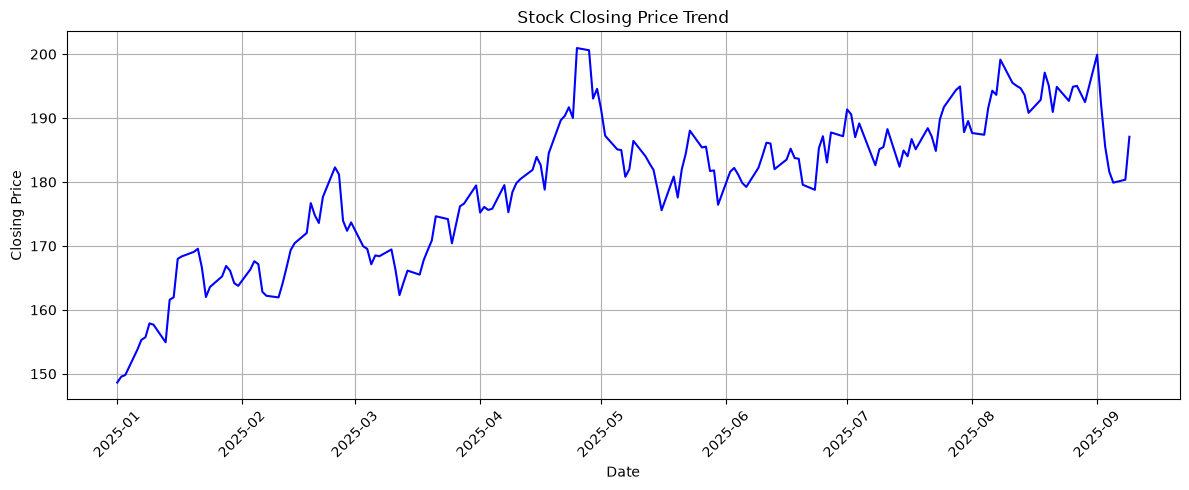

In [9]:
# Let's visualize how the stock price changes over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Close"], color="blue")

plt.title("Stock Closing Price Trend")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

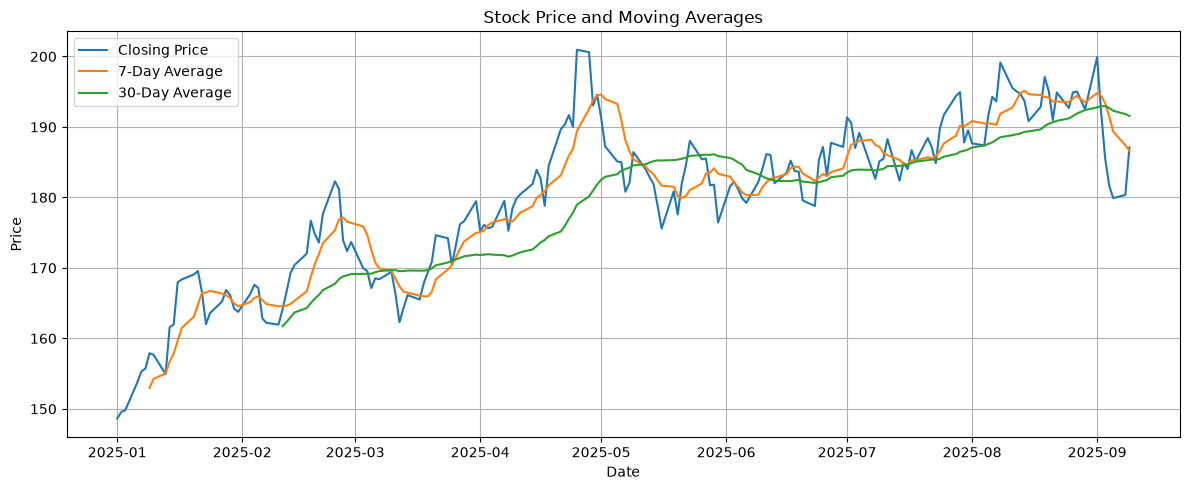

In [10]:
# Let's compare closing prices with moving averages

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Close"], label="Closing Price")
plt.plot(df["Date"], df["MA_7"], label="7-Day Average")
plt.plot(df["Date"], df["MA_30"], label="30-Day Average")

plt.title("Stock Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

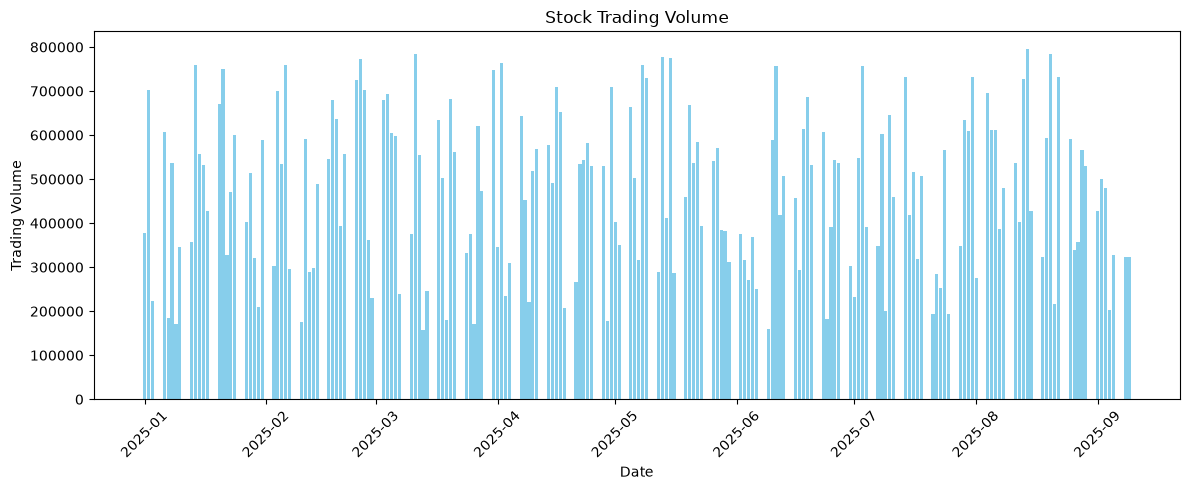

In [11]:
# Let's check how trading volume changes over time

plt.figure(figsize=(12, 5))

plt.bar(df["Date"], df["Volume"], color="skyblue")

plt.title("Stock Trading Volume")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

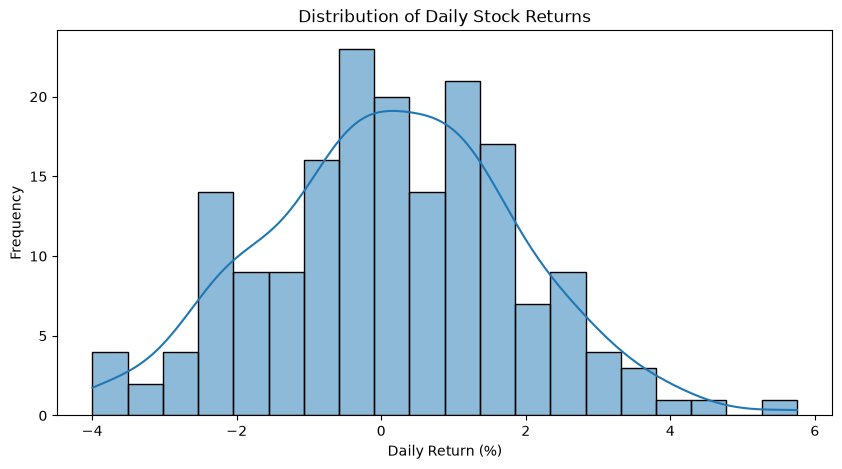

In [12]:
# Let's understand the distribution of daily returns

plt.figure(figsize=(10, 5))

sns.histplot(df["Daily_Return"].dropna(), bins=20, kde=True)

plt.title("Distribution of Daily Stock Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")

plt.show()

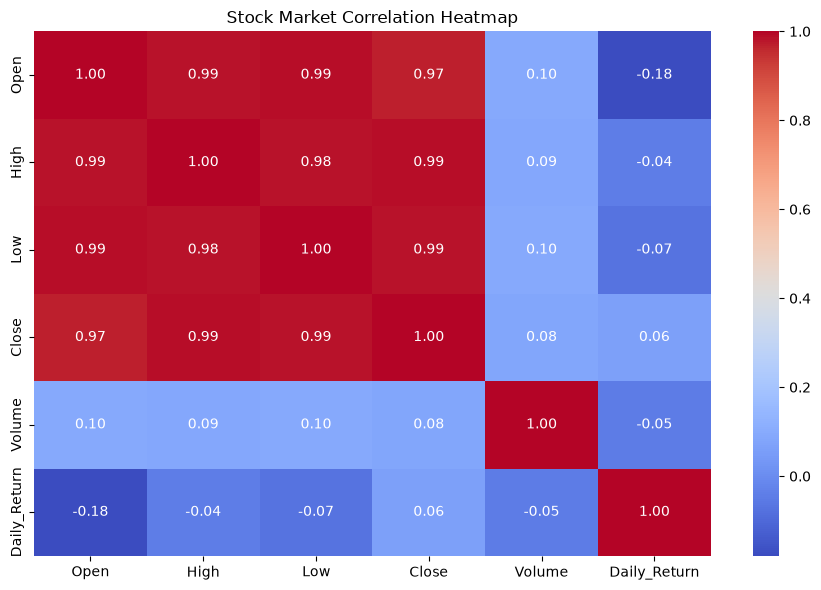

In [13]:
# Let's see how different stock market variables are related

columns = ["Open", "High", "Low", "Close", "Volume", "Daily_Return"]

correlation = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Stock Market Correlation Heatmap")

plt.tight_layout()
plt.show()

Monthly Average Closing Price:
Month
2025-01    160.877391
2025-02    170.839500
2025-03    170.016190
2025-04    184.498636
2025-05    182.953636
2025-06    183.302857
2025-07    187.633478
2025-08    193.484762
2025-09    186.627143
Freq: M, Name: Close, dtype: float64


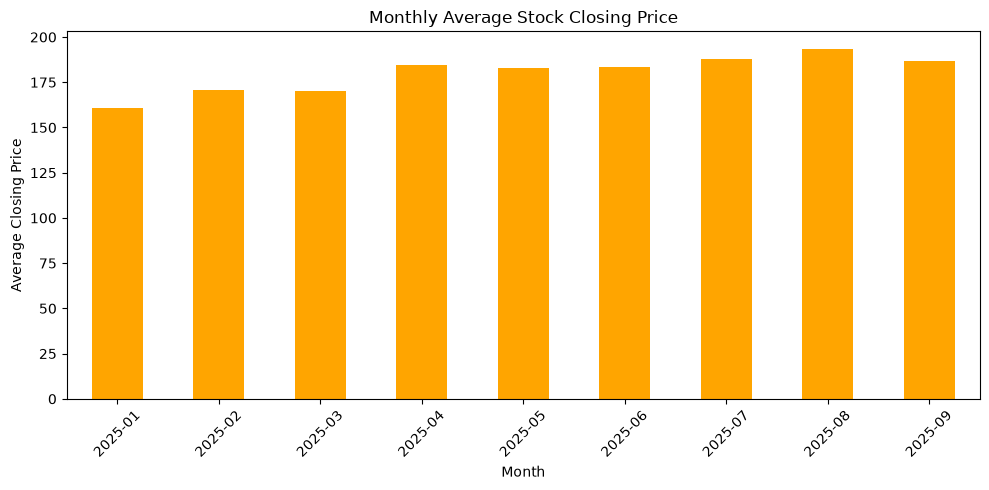

In [14]:
# Let's check the average closing price for each month

df["Month"] = df["Date"].dt.to_period("M")

monthly_data = df.groupby("Month")["Close"].mean()

print("Monthly Average Closing Price:")
print(monthly_data)

monthly_data.plot(kind="bar", figsize=(10, 5), color="orange")

plt.title("Monthly Average Stock Closing Price")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
# Let's find the best and worst trading days

best_day = df.loc[df["Daily_Return"].idxmax()]
worst_day = df.loc[df["Daily_Return"].idxmin()]

print("Best Trading Day:")
print(best_day["Date"])
print("Return:", round(best_day["Daily_Return"], 2), "%")

print("\nWorst Trading Day:")
print(worst_day["Date"])
print("Return:", round(worst_day["Daily_Return"], 2), "%")

Best Trading Day:
2025-04-25 00:00:00
Return: 5.75 %

Worst Trading Day:
2025-02-26 00:00:00
Return: -4.0 %


In [16]:
# Let's calculate overall stock performance

first_price = df["Close"].iloc[0]
last_price = df["Close"].iloc[-1]

overall_return = ((last_price - first_price) / first_price) * 100

print("Starting Closing Price:", round(first_price, 2))
print("Ending Closing Price:", round(last_price, 2))
print("Overall Return:", round(overall_return, 2), "%")

Starting Closing Price: 148.63
Ending Closing Price: 187.08
Overall Return: 25.87 %


In [ ]:


df.to_csv("analyzed_stock_data.csv", index=False)

print("Stock market analysis completed successfully!")
print("Analyzed dataset saved successfully!")

Stock market analysis completed successfully!
Analyzed dataset saved successfully!
